In [22]:
import os

import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from torch.utils.data import DataLoader,Dataset
from torchvision import transforms,models
from sklearn.metrics import accuracy_score

In [23]:
class LungCancerDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        class_map = {
            "Benign cases": 0,
            "Malignant cases": 1,
            "Normal cases": 2
        }

        for class_name, label in class_map.items():
            class_dir = os.path.join(root_dir, class_name)
            for img_name in os.listdir(class_dir):
                self.image_paths.append(os.path.join(class_dir, img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


Using: cpu


In [25]:
from torch.utils.data import WeightedRandomSampler
from collections import Counter

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                     std=[0.229, 0.224, 0.225])
])

train_dataset = LungCancerDataset(root_dir=r'C:\Projects\python\data_sets\lung_cancer_dataset2\train',transform=transform)
test_dataset = LungCancerDataset(root_dir='C:\\Projects\\python\\data_sets\\lung_cancer_dataset2\\test',transform=transform)
val_dataset = LungCancerDataset(root_dir='C:\\Projects\\python\\data_sets\\lung_cancer_dataset2\\validation',transform=transform)


class_counts = Counter(train_dataset.labels)
class_weights = {cls: 1.0/count for cls, count in class_counts.items()}
sample_weights = [class_weights[label] for label in train_dataset.labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler)

####train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features,3)
model = model.to(device)

In [26]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [ ]:
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images,labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs,labels)
        loss.backward()

        optimizer.step()
        running_loss += loss

    print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader)}')

Epoch 1/15, Loss: 0.34972086548805237


In [ ]:
model.eval()
val_labels = []
val_preds = []

with torch.no_grad():
    for images,labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _,preds = torch.max(outputs,1)

        val_labels.extend(labels.cpu().numpy())
        val_preds.extend(preds.cpu().numpy())

    val_accuracy = accuracy_score(val_labels,val_preds)
    print('Validation accuracy:',val_accuracy)

Validation accuracy: 0.9866999168744804


In [ ]:
model.eval()
test_labels = []
test_preds = []


with torch.no_grad():
    for images,labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _,preds = torch.max(outputs,1)

        test_labels.extend(labels.cpu().numpy())
        test_preds.extend(preds.cpu().numpy())

    test_accuracy = accuracy_score(test_labels,test_preds)
    print('Test accuracy:',test_accuracy)

Test accuracy: 0.9878082571349405


In [ ]:
torch.save(model.state_dict(),'lungcancer_classifier3.pth')

In [ ]:
from torchvision import models
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Example model architecture (must match the one you trained!)
model = models.resnet18(pretrained=False)
model.fc = nn.Linear(512, 3)   # Change number of classes accordingly (e.g., 3 lung cancer types)

model.load_state_dict(torch.load("C:\\Projects\\python\\deep_learning\\chest_xray_phneumonia_detection_CNN\\lungcancer_classifier.pth", map_location=device))
model = model.to(device)
model.eval()


c:\Users\jorda\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\jorda\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
from PIL import Image
from torchvision import transforms
import torch

img_path = "C:\\Users\\jorda\\Downloads\\lc1.jpeg"

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225])
])

image = Image.open(img_path).convert('RGB')
image = transform(image).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(image)
    _, predicted = torch.max(output, 1)
    print("Predicted Label:", predicted.item())


Predicted Label: 2


In [ ]:
from collections import Counter

print("Train:", Counter(train_dataset.labels))
print("Val:", Counter(val_dataset.labels))
print("Test:", Counter(test_dataset.labels))


Train: Counter({2: 1208, 1: 1201, 0: 1200})
Val: Counter({2: 1208, 1: 1201, 0: 1200})
Test: Counter({2: 1208, 1: 1201, 0: 1200})


Predicted Class: 2
✅ Heatmap saved at: heatmap_output_fixed.jpg


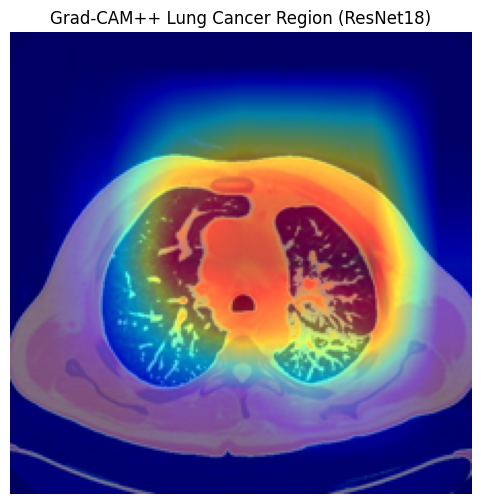

In [ ]:
# ============================================================
# 🔥 Grad-CAM++ Visualization for Lung Cancer Detection (ResNet18)
# ============================================================

import cv2
import numpy as np
import torch
from torchvision import transforms
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from PIL import Image
import matplotlib.pyplot as plt

# --- Load image ---
img_path = r"C:\Projects\python\data_sets\lung_cancer_dataset\test\Malignant cases\Malignant case (523)_9.jpg"   # change to your image path
img = Image.open(img_path).convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
input_tensor = transform(img).unsqueeze(0).to(device)

# --- Predict class ---
model.eval()
with torch.no_grad():
    outputs = model(input_tensor)
    prediction_class = torch.argmax(outputs, dim=1).item()

print(f"Predicted Class: {prediction_class}")

# --- Select last convolutional layer ---
target_layer = model.layer4[-1]

# --- Initialize GradCAM++ ---
cam = GradCAMPlusPlus(model=model, target_layers=[target_layer])

# --- Generate CAM ---
targets = [ClassifierOutputTarget(prediction_class)]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets, eigen_smooth=True)[0, :]

# --- Overlay heatmap ---
rgb_img = np.array(img.resize((224, 224))) / 255.0
heatmap = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# --- Save and show ---
output_path = "heatmap_output_fixed.jpg"
cv2.imwrite(output_path, cv2.cvtColor(heatmap, cv2.COLOR_RGB2BGR))
print(f"✅ Heatmap saved at: {output_path}")

plt.figure(figsize=(6, 6))
plt.imshow(heatmap)
plt.title("Grad-CAM++ Lung Cancer Region (ResNet18)")
plt.axis("off")
plt.show()
